> **Project type: Simulation-based learning project.** This project uses simulated data for 10,000 users to estimate the average effect of issuing coupons on subsequent customer spending. All results are based on simulated data and do not represent actual business outcomes at any company.

In this case study, I walk through a simplified causal inference project to demonstrate how doubly robust estimation can estimate the average effect of issuing coupons on customer spending.

Consider an e-commerce platform that has already distributed coupons to some customers. Customers with higher historical spending and engagement were more likely to receive them. Because these characteristics also influence subsequent spending, directly comparing coupon recipients with non-recipients could produce a biased estimate. Ideally, the platform would have run a randomized A/B test; here, I focus on estimating the effect using observational data.

I use a simulated dataset of 10,000 users containing historical spending, pre-treatment engagement, coupon assignment, and subsequent spending. The analysis combines propensity score and outcome models, with cross-fitting and diagnostics to assess overlap, covariate balance, and model performance.

**How to follow along:** each numbered step contains the question, executable Python code, actual output, and an interpretation. Run the code blocks in order in one Python session. The page shows saved results; it does not execute Python in your browser.

[Download the complete notebook with outputs](Coupon_DRE_Complete_Project.ipynb) · [Dependencies](requirements.txt)

Install the dependencies before running the Python cells:

```bash
pip install numpy pandas scikit-learn matplotlib jupyter
```

## 1. Define the causal question and assumptions

**Question:** what would happen to average subsequent spending if all users in the target population were issued a coupon, compared with none being issued a coupon?

The estimand is the population average treatment effect, `ATE = E[Y(1) - Y(0)]`. Treatment means **issuing** a coupon, not redeeming one. Spending is measured in arbitrary monetary units; this simulation does not specify a real currency or observation window.

| Variable | Meaning | Timing |
|---|---|---|
| `past_spend` | Historical spending | Before coupon assignment |
| `activity` | Historical engagement | Before coupon assignment |
| `treatment` | Coupon issued: 1; no coupon: 0 | Assignment |
| `outcome` | Subsequent spending | After assignment |

Causal interpretation requires:

- **Conditional exchangeability:** after adjusting for historical spending and engagement, there are no remaining common causes of coupon assignment and spending. The simulation ensures this; real data require domain knowledge and additional assessment.
- **Positivity / overlap:** users with the relevant backgrounds have a nonzero probability of either treatment state.
- **Consistency and no interference:** the treatment is well-defined, and one user's coupon does not change another user's outcome.
- **Appropriate sampling and timing:** users are independent units here, and all adjustment variables are measured before treatment.

A high prediction score cannot establish these assumptions. This project uses propensity scores for weighting and AIPW, rather than propensity score matching (PSM).


## 2. Generate the simulated data

**Goal:** create a setting where the true treatment effect is known, so we can compare estimates with the truth.

Historical spending and engagement both increase the chance of receiving a coupon and the amount a user would spend. Engagement also changes the coupon's effect: `true_effect = 10 + 2 * activity`.

The population ATE is 20 because engagement is drawn uniformly from the integers 0 through 10. The mean true effect in one random sample can differ slightly from that population value.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, mean_absolute_error, mean_squared_error
from sklearn.calibration import calibration_curve

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
rng = np.random.default_rng(42)
n = 10000
past_spend = rng.uniform(0, 200, n)
activity = rng.integers(0, 11, n)
log_odds = -2 + 0.01 * past_spend + 0.2 * activity
true_ps = 1 / (1 + np.exp(-log_odds))
treatment = rng.binomial(1, true_ps)
baseline = 20 + 0.5 * past_spend + 5 * activity
true_effect = 10 + 2 * activity
noise = rng.normal(0, 10, n)
outcome = baseline + treatment * true_effect + noise
df = pd.DataFrame({'past_spend': past_spend, 'activity': activity,
                   'treatment': treatment, 'outcome': outcome})
true_sample_ate = true_effect.mean()
true_population_ate = 20.0
print(df.head().round(2))
print('Sample true effect:', round(true_sample_ate, 3), '| Population ATE:', true_population_ate)

   past_spend  activity  treatment  outcome
0      154.79         0          0    87.18
1       87.78         7          1   116.85
2      171.72         2          1   135.20
3      139.47         7          0   124.50
4       18.84         6          0    54.65
Sample true effect: 20.065 | Population ATE: 20.0


**Interpretation.** The first rows show the four observed columns. We also retain the known treatment-effect mechanism for evaluation. The sample's mean true effect is approximately **20.065**; the population ATE is **20.000**. The true propensity score and true effect are not passed to the fitted models.


## 3. Check the data and the raw spending difference

**Goal:** check basic data quality and see what a simple treated-versus-control comparison would report.

Each row is one simulated user. Real data would also require checks for unique user IDs, duplicate coupon assignments, missingness mechanisms, and a consistent follow-up window.


In [2]:
assert not df.isna().any().any()
assert set(df['treatment'].unique()) == {0, 1}
assert np.isfinite(df.to_numpy()).all()
print(df.groupby('treatment').agg(n=('outcome', 'size'), past_spend=('past_spend', 'mean'),
      activity=('activity', 'mean'), outcome=('outcome', 'mean')).round(3))
naive_difference = df.loc[df.treatment == 1, 'outcome'].mean() - df.loc[df.treatment == 0, 'outcome'].mean()
print('Naive difference:', round(naive_difference, 3))

              n  past_spend  activity  outcome
treatment                                     
0          5016      84.870     4.178   83.326
1          4984     114.072     5.893  128.515
Naive difference: 45.19


**Interpretation.** Coupon recipients have higher historical spending (**114.072 versus 84.870**) and engagement (**5.893 versus 4.178**). Their subsequent spending is higher by about **45.190** units. Since the known effect is around 20, that raw comparison substantially overstates the coupon effect in this simulation. It mixes treatment with pre-existing differences.


## 4. Train the models with cross-fitting

**Goal:** predict each user's propensity score and expected outcomes without using that user's labels to train the models.

| Model | Training rows within each training fold | Prediction for every held-out user |
|---|---|---|
| Propensity model | All training users | `ps`: probability of receiving a coupon |
| Outcome model 0 | Training users with `treatment = 0` | `mu0`: expected spending without a coupon |
| Outcome model 1 | Training users with `treatment = 1` | `mu1`: expected spending with a coupon |

I use a logistic regression pipeline for propensity scores and a separate linear regression for each outcome state. Five-fold cross-fitting trains on 80% of users and predicts for the remaining 20%, repeating until every user has one held-out prediction.

The two outcome models **predict** on the validation users; their predictions are not used to train those same models again. I also produce training-fold constant predictions as simple baselines.


In [3]:
def cross_fit(data, ps_cols, outcome_cols, seed=42):
    T = data['treatment'].to_numpy()
    Y = data['outcome'].to_numpy()
    pred = {name: np.full(len(data), np.nan) for name in
            ['ps', 'mu0', 'mu1', 'base_ps', 'base0', 'base1']}
    counts = np.zeros(len(data), dtype=int)
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    for train_idx, valid_idx in folds.split(data, T):
        train = data.iloc[train_idx]
        valid = data.iloc[valid_idx]
        ps_model = Pipeline([('scaler', StandardScaler()),
                             ('model', LogisticRegression(max_iter=1000))])
        ps_model.fit(train[ps_cols], train['treatment'])
        pred['ps'][valid_idx] = ps_model.predict_proba(valid[ps_cols])[:, 1]
        pred['base_ps'][valid_idx] = train['treatment'].mean()
        for state in [0, 1]:
            group = train.loc[train['treatment'] == state]
            model = LinearRegression()
            model.fit(group[outcome_cols], group['outcome'])
            pred[f'mu{state}'][valid_idx] = model.predict(valid[outcome_cols])
            pred[f'base{state}'][valid_idx] = group['outcome'].mean()
        counts[valid_idx] += 1
    assert (counts == 1).all()  # Each user receives exactly one held-out prediction
    assert all(np.isfinite(v).all() for v in pred.values())
    return pred

features = ['past_spend', 'activity']
pred = cross_fit(df, features, features)
for name in ['ps', 'mu0', 'mu1']:
    df[name] = pred[name]
print(df[['treatment', 'outcome', 'ps', 'mu0', 'mu1']].head().round(3))

   treatment  outcome     ps      mu0      mu1
0          0   87.185  0.391   97.504  107.908
1          1  116.848  0.564   98.809  123.088
2          1  135.199  0.530  115.895  130.228
3          0  124.498  0.687  124.772  148.848
4          0   54.646  0.348   59.539   81.767


**Interpretation.** Every user now has an out-of-fold `ps`, `mu0`, and `mu1`. For a treated user, `mu0` is a counterfactual prediction; for an untreated user, `mu1` is counterfactual. These are conditional expected outcomes, not observations of both potential outcomes. The assertions verify that each user was held out exactly once and all predictions are finite.

Cross-fitting addresses reuse of observations in model fitting and estimation. It does not remove unmeasured confounding or create missing comparison groups.


## 5. Evaluate the propensity score model

**Goal:** evaluate the quality of the out-of-fold treatment probabilities, relative to a constant baseline.

AUC measures discrimination. Brier score and log loss assess probability prediction and reflect both calibration and discrimination. The calibration table and plot compare predicted treatment probabilities with observed treatment rates, using approximately equal-sized bins.


                   model  ROC_AUC   Brier  Log_loss
0                 OOF PS   0.7136  0.2153    0.6192
1  OOF constant baseline   0.4998  0.2500    0.6931
                   n  predicted  observed
bin                                      
(0.118, 0.239]  1000      0.190     0.188
(0.239, 0.317]  1000      0.278     0.281
(0.317, 0.385]  1000      0.351     0.364
(0.385, 0.446]  1000      0.417     0.412
(0.446, 0.498]  1000      0.473     0.486
(0.498, 0.552]  1000      0.526     0.523
(0.552, 0.61]   1000      0.582     0.556
(0.61, 0.679]   1000      0.645     0.638
(0.679, 0.758]  1000      0.716     0.691
(0.758, 0.881]  1000      0.808     0.845


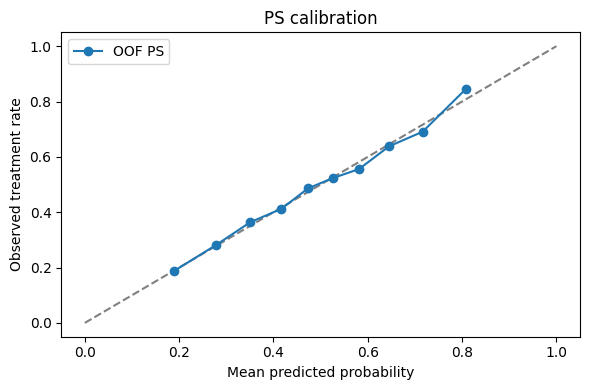

In [4]:
T = df['treatment'].to_numpy()
Y = df['outcome'].to_numpy()
ps = df['ps'].to_numpy()
ps_metrics = pd.DataFrame([
    {'model': name, 'ROC_AUC': roc_auc_score(T, p), 'Brier': brier_score_loss(T, p),
     'Log_loss': log_loss(T, p)}
    for name, p in [('OOF PS', ps), ('OOF constant baseline', pred['base_ps'])]])
print(ps_metrics.round(4))
calibration = pd.DataFrame({'ps': ps, 'T': T})
calibration['bin'] = pd.qcut(ps, 10, duplicates='drop')
print(calibration.groupby('bin', observed=True).agg(n=('T', 'size'), predicted=('ps', 'mean'),
      observed=('T', 'mean')).round(3))
observed, predicted = calibration_curve(T, ps, n_bins=10, strategy='quantile')
plt.figure(figsize=(6, 4))
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.plot(predicted, observed, 'o-', label='OOF PS')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed treatment rate')
plt.title('PS calibration'); plt.legend(); plt.tight_layout(); plt.show()

**Interpretation.** The fitted PS model improves on the constant baseline: Brier score falls from **0.2500 to 0.2153**, and log loss from **0.6931 to 0.6192**. Calibration is broadly close to the diagonal, although some bins differ. Inspect those discrepancies and their sample counts rather than requiring every point to match perfectly.

An AUC of **0.7136** describes treatment discrimination, not the credibility of the causal estimate. AUC should not be maximized as the sole objective: near-perfect discrimination can accompany poor overlap. I evaluate overlap, weight stability, and balance separately.


## 6. Check overlap

**Goal:** inspect whether the data contain both treatment states for comparable users.

I compare propensity score distributions by treatment and count users in a coarse historical-spending-by-engagement grid. Neither diagnostic proves support in every covariate region. The `[0.05, 0.95]` range is an illustrative tail check, not a universal acceptance rule. No users are automatically removed.


Counts by PS bin:
 col_0         0    1
row_0               
(0.1, 0.2]  476  103
(0.2, 0.3]  907  306
(0.3, 0.4]  926  520
(0.4, 0.5]  977  818
(0.5, 0.6]  835  955
(0.6, 0.7]  519  950
(0.7, 0.8]  318  853
(0.8, 0.9]   58  479
Share with PS outside [0.05, 0.95]: 0.0
Covariate grid counts (coarse diagnostic only):
 treatment                  0    1
past_spend     activity          
(-0.001, 50.0] (-1, 3]   733  187
               (3, 7]    580  313
               (7, 10]   384  348
(50.0, 100.0]  (-1, 3]   638  247
               (3, 7]    491  419
               (7, 10]   243  432
(100.0, 150.0] (-1, 3]   532  358
               (3, 7]    400  550
               (7, 10]   188  515
(150.0, 200.0] (-1, 3]   448  476
               (3, 7]    291  580
               (7, 10]    88  559


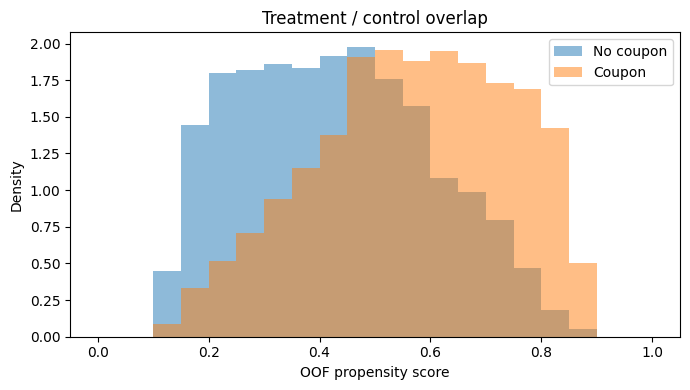

In [5]:
bins = np.linspace(0, 1, 11)
ps_bins = pd.cut(ps, bins=bins, include_lowest=True)
overlap_counts = pd.crosstab(ps_bins, T).reindex(columns=[0, 1], fill_value=0)
print('Counts by PS bin:\n', overlap_counts)
print('Share with PS outside [0.05, 0.95]:', round(np.mean((ps < .05) | (ps > .95)), 4))
spend_bin = pd.cut(df.past_spend, bins=[0, 50, 100, 150, 200], include_lowest=True)
activity_bin = pd.cut(df.activity, bins=[-1, 3, 7, 10])
support_grid = pd.crosstab([spend_bin, activity_bin], df.treatment).reindex(columns=[0, 1], fill_value=0)
print('Covariate grid counts (coarse diagnostic only):\n', support_grid)
plt.figure(figsize=(7, 4))
for state, label in [(0, 'No coupon'), (1, 'Coupon')]:
    plt.hist(ps[T == state], bins=np.linspace(0, 1, 21), density=True, alpha=.5, label=label)
plt.xlabel('OOF propensity score'); plt.ylabel('Density'); plt.legend()
plt.title('Treatment / control overlap'); plt.tight_layout(); plt.show()

**Interpretation.** Both groups appear across a broad range of propensity scores. No estimated score falls outside `[0.05, 0.95]`, and both groups appear in every checked covariate-grid cell. The high-propensity tail has fewer controls, so the aggregate overlap plot should still be read alongside counts and the weighting diagnostics.

Overlap also matters for outcome regression. A model predicting a counterfactual for users unlike its training group may be extrapolating, even if its factual validation error is low.


## 7. Inspect weights, ESS, and covariate balance

**Goal:** check whether inverse-probability weighting is dominated by a few users and whether it reduces observed differences between groups.

Treated users receive weight `1 / ps`; untreated users receive weight `1 / (1 - ps)`. This example does not clip weights. The function refuses exact zero or one probabilities rather than silently changing them.

Effective sample size is `ESS = (sum(w) ** 2) / sum(w ** 2)`. It measures weight concentration, not exact statistical power. I check SMDs for the original features, squared terms, and an interaction. The SMD denominator is held fixed at the pre-weighting pooled standard deviation to make before-and-after values comparable.


   T     n   mean   p99    max       ESS  ESS_fraction  top_1pct_weight_share
0  0  5016  1.981  5.14  8.317  4232.438         0.844                  0.032
1  1  4984  2.014  5.75  8.285  4102.633         0.823                  0.033
              feature  treated_before  control_before  treated_after  control_after  SMD_before  SMD_after
0          past_spend         114.072          84.870         99.071         98.705       0.524      0.007
1            activity           5.893           4.178          5.012          4.981       0.565      0.010
2  past_spend_squared       16132.333       10301.755      13151.583      13036.458       0.506      0.010
3    activity_squared          44.012          26.606         35.147         34.512       0.548      0.020
4    spend_x_activity         660.093         337.536        497.676        482.729       0.746      0.035


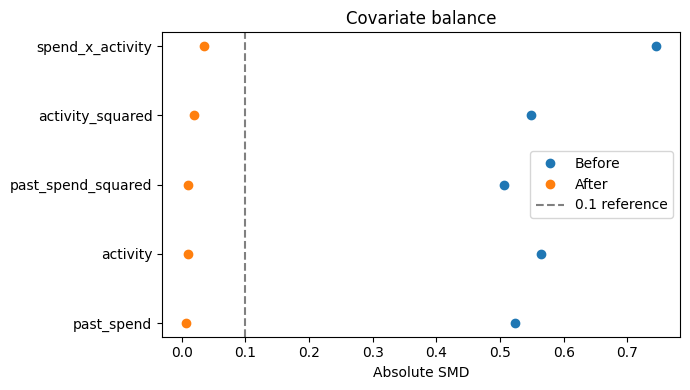

In [6]:
def weights_from_ps(t, p):
    if not np.all((p > 0) & (p < 1)):
        raise ValueError('PS contains 0 or 1: inspect support/model before estimating.')
    return np.where(t == 1, 1 / p, 1 / (1 - p))

def weight_diagnostics(t, w):
    rows = []
    for state in [0, 1]:
        a = w[t == state]
        ess = a.sum() ** 2 / np.square(a).sum()
        rows.append({'T': state, 'n': len(a), 'mean': a.mean(), 'p99': np.quantile(a, .99),
                     'max': a.max(), 'ESS': ess, 'ESS_fraction': ess / len(a),
                     'top_1pct_weight_share': np.sort(a)[-max(1, int(np.ceil(.01*len(a)))):].sum()/a.sum()})
    return pd.DataFrame(rows)

def balance_diagnostics(data, t, w):
    check = data[features].copy()
    check['past_spend_squared'] = data.past_spend ** 2
    check['activity_squared'] = data.activity ** 2
    check['spend_x_activity'] = data.past_spend * data.activity
    rows = []
    for col in check:
        a = check.loc[t == 1, col].to_numpy()
        b = check.loc[t == 0, col].to_numpy()
        sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
        wa = np.average(a, weights=w[t == 1])
        wb = np.average(b, weights=w[t == 0])
        rows.append({'feature': col, 'treated_before': a.mean(), 'control_before': b.mean(),
                     'treated_after': wa, 'control_after': wb,
                     'SMD_before': (a.mean()-b.mean())/sd if sd else np.nan,
                     'SMD_after': (wa-wb)/sd if sd else np.nan})
    return pd.DataFrame(rows)

w = weights_from_ps(T, ps)
df['weight'] = w
weight_table = weight_diagnostics(T, w)
balance_table = balance_diagnostics(df, T, w)
print(weight_table.round(3))
print(balance_table.round(3))
plt.figure(figsize=(7, 4))
plt.plot(balance_table.SMD_before.abs(), balance_table.feature, 'o', label='Before')
plt.plot(balance_table.SMD_after.abs(), balance_table.feature, 'o', label='After')
plt.axvline(.1, ls='--', color='gray', label='0.1 reference')
plt.xlabel('Absolute SMD'); plt.title('Covariate balance'); plt.legend(); plt.tight_layout(); plt.show()

**Interpretation.** The effective sample sizes are approximately **4,232 controls** and **4,103 treated users**, or 84.4% and 82.3% of their original groups. The largest weight is approximately **8.317**. The heaviest 1% of users account for roughly 3.2–3.3% of group weight.

The checked terms become more balanced after weighting: the maximum absolute SMD falls from approximately **0.746 to 0.0346**. The dashed 0.1 line is a common rule of thumb, not a guarantee of identification. Checking means and a few transformed features cannot prove complete joint-distribution balance or balance on unobserved variables.


## 8. Evaluate the outcome models

**Goal:** check held-out prediction errors in the treatment state we actually observe.

For users with `treatment = 0`, compare `mu0` with actual spending. For users with `treatment = 1`, compare `mu1` with actual spending. Compare each model against its training-group mean baseline, then inspect residuals across feature ranges.

MAE is the mean absolute prediction error. RMSE gives larger errors more weight. Residuals are `actual - predicted`.


   state                         model     n     MAE    RMSE  mean_residual
0      0                 Outcome model  5016   7.910   9.971          0.002
1      0  Training-group mean baseline  5016  26.418  31.918          0.000
2      1                 Outcome model  4984   8.187  10.230          0.001
3      1  Training-group mean baseline  4984  28.712  35.232         -0.000
Residuals by past_spend
                                 n  mean_residual  residual_sd
treatment bin                                                 
0         (0.0619, 49.208]    1668         -0.047       10.078
          (49.208, 99.66]     1393          0.273        9.952
          (99.66, 149.136]    1106         -0.096        9.951
          (149.136, 199.995]   849         -0.218        9.828
1         (0.0619, 49.208]     832         -0.036       10.109
          (49.208, 99.66]     1107         -0.016       10.092
          (99.66, 149.136]    1394         -0.124       10.616
          (149.136, 199.995] 

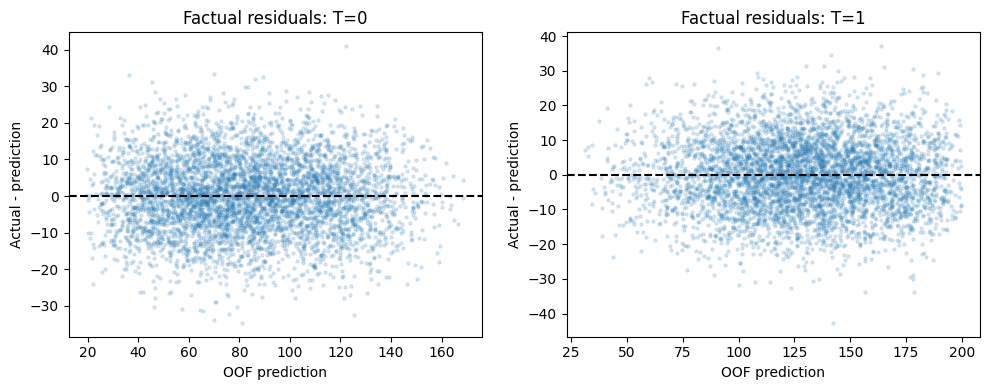

In [7]:
outcome_rows = []
for state in [0, 1]:
    mask = T == state
    for label, values in [('Outcome model', pred[f'mu{state}']),
                          ('Training-group mean baseline', pred[f'base{state}'])]:
        outcome_rows.append({'state': state, 'model': label, 'n': mask.sum(),
            'MAE': mean_absolute_error(Y[mask], values[mask]),
            'RMSE': np.sqrt(mean_squared_error(Y[mask], values[mask])),
            'mean_residual': (Y[mask]-values[mask]).mean()})
outcome_metrics = pd.DataFrame(outcome_rows)
print(outcome_metrics.round(3))
factual_prediction = np.where(T == 1, pred['mu1'], pred['mu0'])
residuals = df[['treatment', 'past_spend', 'activity']].copy()
residuals['residual'] = Y - factual_prediction
for col in features:
    residuals['bin'] = pd.qcut(residuals[col], 4, duplicates='drop')
    print('Residuals by', col)
    print(residuals.groupby(['treatment', 'bin'], observed=True).agg(
        n=('residual', 'size'), mean_residual=('residual', 'mean'),
        residual_sd=('residual', 'std')).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for state, ax in zip([0, 1], axes):
    mask = T == state
    ax.scatter(factual_prediction[mask], (Y-factual_prediction)[mask], s=5, alpha=.15)
    ax.axhline(0, color='black', ls='--')
    ax.set(xlabel='OOF prediction', ylabel='Actual - prediction', title=f'Factual residuals: T={state}')
plt.tight_layout(); plt.show()

**Interpretation.** The outcome-model MAEs are approximately **7.910** without coupons and **8.187** with coupons, compared with baseline MAEs of **26.418** and **28.712**. The fitted models predict factual spending substantially better than a group-mean guess. Mean residuals are close to zero; the binned residual checks help reveal whether that average conceals systematic errors in some regions.

A treated user's actual spending **cannot validate `mu0`**, because it was observed under treatment. Good factual prediction does not directly establish counterfactual accuracy. There is no universal MAE cutoff that certifies a model for causal inference.


## 9. Estimate ATE with AIPW

**Goal:** combine the predicted outcome difference with propensity-weighted residual corrections.

```text
AIPW score = mu1 - mu0
           + T * (Y - mu1) / ps
           - (1 - T) * (Y - mu0) / (1 - ps)

ATE estimate = mean(AIPW scores)
```

The first term is the difference between predicted expected outcomes. The two correction terms use observed-state prediction errors. An individual score is a contribution to the population estimate, not an identified personal treatment effect.

For comparison, I also compute the naive difference, normalized IPW (Hájek), and the outcome-only estimate.


In [8]:
def aipw_scores(y, t, p, m0, m1):
    weights_from_ps(t, p)  # Validate probabilities; do not silently clip them
    return m1-m0 + t*(y-m1)/p - (1-t)*(y-m0)/(1-p)

ipw_ate = np.average(Y[T == 1], weights=w[T == 1]) - np.average(Y[T == 0], weights=w[T == 0])
df['predicted_effect'] = df.mu1 - df.mu0
df['correction_1'] = T * (Y-df.mu1) / ps
df['correction_0'] = (1-T) * (Y-df.mu0) / (1-ps)
df['dr_score'] = aipw_scores(Y, T, ps, pred['mu0'], pred['mu1'])
dr_ate = df.dr_score.mean()
se = df.dr_score.std(ddof=1) / np.sqrt(n)
ci_low, ci_high = dr_ate - 1.96*se, dr_ate + 1.96*se
ate_table = pd.DataFrame({'method': ['Naive', 'Normalized IPW', 'Outcome only', 'AIPW'],
    'estimate': [naive_difference, ipw_ate, df.predicted_effect.mean(), dr_ate]})
ate_table['error_vs_sample_truth'] = ate_table.estimate - true_sample_ate
print(ate_table.round(3))
print(f'AIPW population-ATE approximate 95% CI: [{ci_low:.3f}, {ci_high:.3f}]; SE={se:.3f}')
print('Mean correction:', round((df.correction_1-df.correction_0).mean(), 5))

           method  estimate  error_vs_sample_truth
0           Naive    45.190                 25.125
1  Normalized IPW    20.696                  0.631
2    Outcome only    20.400                  0.334
3            AIPW    20.394                  0.329
AIPW population-ATE approximate 95% CI: [19.949, 20.839]; SE=0.227
Mean correction: -0.00543


**Interpretation.** AIPW estimates an average spending increase of approximately **20.394**, compared with **45.190** from the naive difference and a known population effect of **20.000**. The sample's true mean effect is **20.065**, a related but different target.

The approximate 95% interval for the **population ATE** is **[19.949, 20.839]**, with standard error about **0.227**. It uses the empirical standard deviation of the scores, divided by the square root of the user count. This calculation relies on independent users, cross-fitting, correctly specified baseline models, and regularity conditions; consistency under one correct nuisance model alone does not automatically validate this simple interval.

The average residual correction is only about **−0.00543** here. AIPW is close to outcome regression because the baseline outcome models already describe the simulated mechanism well. Doubly robust estimation is not guaranteed to beat every alternative in every finite sample.


## 10. Deliberately misspecify the models

**Goal:** illustrate what happens when I omit engagement from one or both sides of the estimator.

The data and fold assignments stay fixed. Only the input features change. In this simulation, using both features correctly specifies the propensity model and both outcome conditional means. Omitting `activity` creates misspecification.


In [9]:
bad_outcome = cross_fit(df, features, ['past_spend'])
bad_ps = cross_fit(df, ['past_spend'], features)
both_bad = cross_fit(df, ['past_spend'], ['past_spend'])
scenarios = [('Both full', pred), ('PS full, outcome omits activity', bad_outcome),
             ('PS omits activity, outcome full', bad_ps), ('Both omit activity', both_bad)]
scenario_rows = []
for label, p in scenarios:
    value = aipw_scores(Y, T, p['ps'], p['mu0'], p['mu1']).mean()
    scenario_rows.append({'scenario': label, 'outcome_only': (p['mu1']-p['mu0']).mean(),
                          'AIPW': value, 'AIPW_error_vs_sample_truth': value-true_sample_ate})
scenario_table = pd.DataFrame(scenario_rows)
print(scenario_table.round(3))
print('Bad-PS weighted balance:')
print(balance_diagnostics(df, T, weights_from_ps(T, bad_ps['ps']))[
    ['feature', 'SMD_before', 'SMD_after']].round(3))
print('Bad-outcome factual MAE by state:')
for state in [0, 1]:
    mask = T == state
    print(state, round(mean_absolute_error(Y[mask], bad_outcome[f'mu{state}'][mask]), 3))

                          scenario  outcome_only    AIPW  AIPW_error_vs_sample_truth
0                        Both full          20.4  20.394                       0.329
1  PS full, outcome omits activity          31.4  20.520                       0.455
2  PS omits activity, outcome full          20.4  20.417                       0.352
3               Both omit activity          31.4  31.416                      11.351
Bad-PS weighted balance:
              feature  SMD_before  SMD_after
0          past_spend       0.524      0.001
1            activity       0.565      0.610
2  past_spend_squared       0.506      0.001
3    activity_squared       0.548      0.593
4    spend_x_activity       0.746      0.441
Bad-outcome factual MAE by state:
0 14.748
1 19.587


**Interpretation.** With one side correctly specified, AIPW remains near the known effect in this run: **20.520** when the outcome model omits engagement, and **20.417** when the PS model omits it. When both sides omit engagement, the estimate rises to **31.416**.

The misspecified PS leaves engagement poorly balanced after weighting (**SMD ≈ 0.610**). The misspecified outcome models also have larger factual MAEs (about **14.748** and **19.587**).

Double robustness is an asymptotic consistency property under the identification assumptions and relevant regularity conditions: a correct propensity model or correct outcome conditional means can suffice. This single simulation illustrates the behavior; it is not a general proof. I do not apply the baseline confidence-interval calculation to these misspecified scenarios.


## 11. Stress-test poor overlap

**Goal:** show a data-support problem that cannot be solved simply by choosing a more complex model.

I change the assignment mechanism so low-spending users almost never receive coupons, while high-spending users almost always do. User backgrounds and the treatment-effect mechanism are retained. This is a second simulated study.

The true assignment probabilities are near zero or one, rather than exactly zero or one. Even so, a finite sample can have regions with no observed controls.


PS outside [0.05, 0.95]: 0.789
   T     n   mean    p99       max      ESS  ESS_fraction  top_1pct_weight_share
0  0  5064  1.327  6.440   247.476  508.408         0.100                  0.153
1  1  4936  1.579  6.179  1180.829   41.622         0.008                  0.291
col_0              0     1
past_spend                
(-0.001, 50.0]  2544     1
(50.0, 100.0]   2266   204
(100.0, 150.0]   254  2289
(150.0, 200.0]     0  2442
Do not treat a computed full-population estimate as reliable without support.


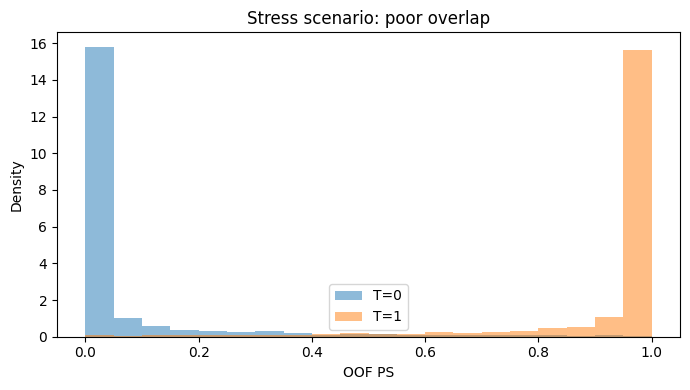

In [10]:
stress = df[['past_spend', 'activity']].copy()
stress_rng = np.random.default_rng(2026)
stress_true_ps = 1/(1+np.exp(-0.15*(stress.past_spend.to_numpy()-100)))
stress_t = stress_rng.binomial(1, stress_true_ps)
stress['treatment'] = stress_t
stress['outcome'] = baseline + stress_t*true_effect + stress_rng.normal(0, 10, n)
stress_pred = cross_fit(stress, features, features)
stress_w = weights_from_ps(stress_t, stress_pred['ps'])
print('PS outside [0.05, 0.95]:', round(np.mean((stress_pred['ps']<.05)|(stress_pred['ps']>.95)), 3))
print(weight_diagnostics(stress_t, stress_w).round(3))
print(pd.crosstab(pd.cut(stress.past_spend, [0, 50, 100, 150, 200], include_lowest=True), stress_t))
plt.figure(figsize=(7, 4))
for state in [0, 1]:
    plt.hist(stress_pred['ps'][stress_t == state], bins=np.linspace(0, 1, 21), alpha=.5,
             density=True, label=f'T={state}')
plt.title('Stress scenario: poor overlap'); plt.xlabel('OOF PS'); plt.ylabel('Density')
plt.legend(); plt.tight_layout(); plt.show()
print('Do not treat a computed full-population estimate as reliable without support.')

**Interpretation.** About **78.9%** of estimated propensity scores are outside `[0.05, 0.95]`. The treated group's ESS collapses to approximately **41.6**, or **0.8%** of the original group. The largest weight is approximately **1,180.8**.

In the highest historical-spending bin, there are **2,442 treated users and no controls**. Counterfactual predictions for this region therefore rely heavily on model extrapolation. Computing a full-population ATE would not, by itself, make that estimate well-supported.

Possible responses include collecting more comparison data, running a randomized experiment, or explicitly redefining the target population to a supported region. Restricting the population changes the estimand. Weight clipping trades bias against variance; it cannot create missing controls or repair a structural positivity violation.


## 12. Summarize the diagnostics

**Goal:** collect the baseline simulation's diagnostic results in one place for review.

These are diagnostic observations rather than an automatic pass/fail certificate. Thresholds for tail probabilities, SMD, or ESS should be chosen in the context of the target population, sample size, and sensitivity analyses.


In [11]:
diagnostics = pd.Series({
    'PS Brier': ps_metrics.loc[0, 'Brier'],
    'PS baseline Brier': ps_metrics.loc[1, 'Brier'],
    'Share PS outside [0.05,0.95]': np.mean((ps<.05)|(ps>.95)),
    'Max absolute weighted SMD (checked terms)': balance_table.SMD_after.abs().max(),
    'Minimum ESS fraction': weight_table.ESS_fraction.min(),
    'Maximum weight': w.max(),
    'AIPW estimate': dr_ate,
    'AIPW approximate CI low': ci_low,
    'AIPW approximate CI high': ci_high,
})
print(diagnostics.round(4))
print('Review terms with |SMD| >= 0.1:',
      balance_table.loc[balance_table.SMD_after.abs() >= .1, 'feature'].tolist())

PS Brier                                      0.2153
PS baseline Brier                             0.2500
Share PS outside [0.05,0.95]                  0.0000
Max absolute weighted SMD (checked terms)     0.0346
Minimum ESS fraction                          0.8232
Maximum weight                                8.3170
AIPW estimate                                20.3943
AIPW approximate CI low                      19.9492
AIPW approximate CI high                     20.8393
dtype: float64
Review terms with |SMD| >= 0.1: []


**Interpretation.** The baseline diagnostics support proceeding with this simulated example: the checked features balance well, weights are not highly concentrated, and the factual outcome models outperform simple baselines. None of these checks proves the absence of unmeasured confounding. In a real study, the design and assumptions still need justification.




**Dependencies used for the saved run:** `numpy==2.3.5`, `pandas==2.2.3`, `scikit-learn==1.8.0`, `matplotlib==3.10.8`.
## What I learned

The raw group difference was about **45.2** spending units, while AIPW estimated approximately **20.4**, close to the known population effect of **20**. The mechanism of the simulation lets me verify how selection bias affects the raw comparison and how adjustment changes it.

The most useful part of the workflow is the connection between diagnostics and interpretation: treatment prediction, overlap, balance, factual outcome accuracy, and uncertainty each answer a different question. A model that produces a number does not necessarily produce a credible causal estimate.

This project estimates the overall ATE. Although the simulated effect varies with engagement, I have not evaluated a separate heterogeneous-treatment-effect estimator here.

Before applying this workflow to real data, I would define the treatment, time zero, follow-up window, and target population; justify the confounder set; check missingness and repeated assignments; use user- or time-based splitting where needed; and choose inference appropriate to the sampling structure. Negative controls or sensitivity analyses can provide additional evidence but do not prove identification. Spending lift also needs to be weighed against coupon cost and margin before making a profit decision.

## Download and edit

Open it in Jupyter and select **Restart Kernel and Run All** to reproduce the analysis. The notebook records the dependency versions used for this run; other versions may produce small numerical differences.

To edit the website article, update this project's `index.md` file on GitHub. Code is inside fenced `python` blocks; saved results are inside fenced `text` blocks; explanations are ordinary Markdown. Changing text in a code block does not run Python or regenerate its output. After changing analysis code, rerun the notebook and update the corresponding outputs and figures before publishing.

## References

- [Funk et al. (2011): Doubly Robust Estimation of Causal Effects](https://pmc.ncbi.nlm.nih.gov/articles/PMC3070495/)
- [Zhong et al. (2021): AIPW: An R Package for Augmented Inverse Probability–Weighted Estimation of Average Causal Effects](https://pmc.ncbi.nlm.nih.gov/articles/PMC8796813/)
- [scikit-learn: Probability calibration](https://scikit-learn.org/stable/modules/calibration.html)
